Odnajdujemy projekt i umożliwiamy import wspólnych modułów.

In [1]:
from pathlib import Path
import sys

project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src/restore_pipeline/super_resolution").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Uruchom notebook wewnątrz katalogu projektu.")

source_path = str(project_root / "src")

if source_path not in sys.path:
    sys.path.insert(0, source_path)


Importujemy wspólną ocenę eksperymentów i podgląd zapisanych raportów.

In [2]:
import torch
from IPython.display import Image as DisplayImage, display
from restore_pipeline.super_resolution.evaluation import benchmark_experiments

from restore_pipeline.super_resolution.paths import display_path


Wybieramy katalogi eksperymentów do pełnej walidacji, wspólny batch size i ograniczony zestaw przykładów.

In [3]:
DATASET_PATH = project_root / "notebooks/igoh/data/partitioned_dataset"
EXPERIMENTS_PATH = project_root / "notebooks/igoh/models_weights/experiments"
RESULTS_PATH = project_root / "notebooks/igoh/data/sr_results"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RUN_PATHS = [
    EXPERIMENTS_PATH / "EDSR4_x2_mse_20261109_192402_212926",
    EXPERIMENTS_PATH / "ESPCN3_x2_mse_20261109_185704_405012",
]
BATCH_SIZE = 64
NUM_WORKERS = 0
PREVIEW_INDICES = [10, 11, 12]
CASE_COUNT = 3
SHOW_PROGRESS = True


Oceniamy najlepsze checkpointy na obrazach pełnej walidacji, mierząc forward po rozgrzewce i licząc bicubic tylko raz.

In [4]:
summary = benchmark_experiments(
    RUN_PATHS,
    DATASET_PATH,
    RESULTS_PATH,
    DEVICE,
    split="val",
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    preview_indices=PREVIEW_INDICES,
    case_count=CASE_COUNT,
    show_progress=SHOW_PROGRESS,
)

display(summary.round(5))


Bicubic:   0%|          | 0/161 [00:00<?, ?partia/s]

Ocena 1/2: EDSR4_x2_mse_20261109_192402_212926


Ocena modelu:   0%|          | 0/161 [00:00<?, ?partia/s]

Ocena 2/2: ESPCN3_x2_mse_20261109_185704_405012


Ocena modelu:   0%|          | 0/161 [00:00<?, ?partia/s]

,method,name,run_path,checkpoint_epoch,MSE,PSNR,SSIM,inference_ms_per_image,parameters,batch_size,num_workers,warmup_batches,device,device_name,label
0,Model,EDSR4,notebooks/igoh/models_weights/experiments/EDSR...,50.0,0.00125,31.30611,0.90698,1.21263,31043,64.0,0.0,3.0,cuda,NVIDIA GeForce GTX 1060 6GB,EDSR4
1,Model,ESPCN3,notebooks/igoh/models_weights/experiments/ESPC...,50.0,0.00141,30.72786,0.90124,0.49766,26796,64.0,0.0,3.0,cuda,NVIDIA GeForce GTX 1060 6GB,ESPCN3
2,Bicubic,Bicubic,NaN,NaN,0.00179,29.62533,0.87094,NaN,0,NaN,NaN,NaN,NaN,NaN,Bicubic


Porównujemy wspólne metryki oraz czas samego forward bez transferów i obliczania metryk.

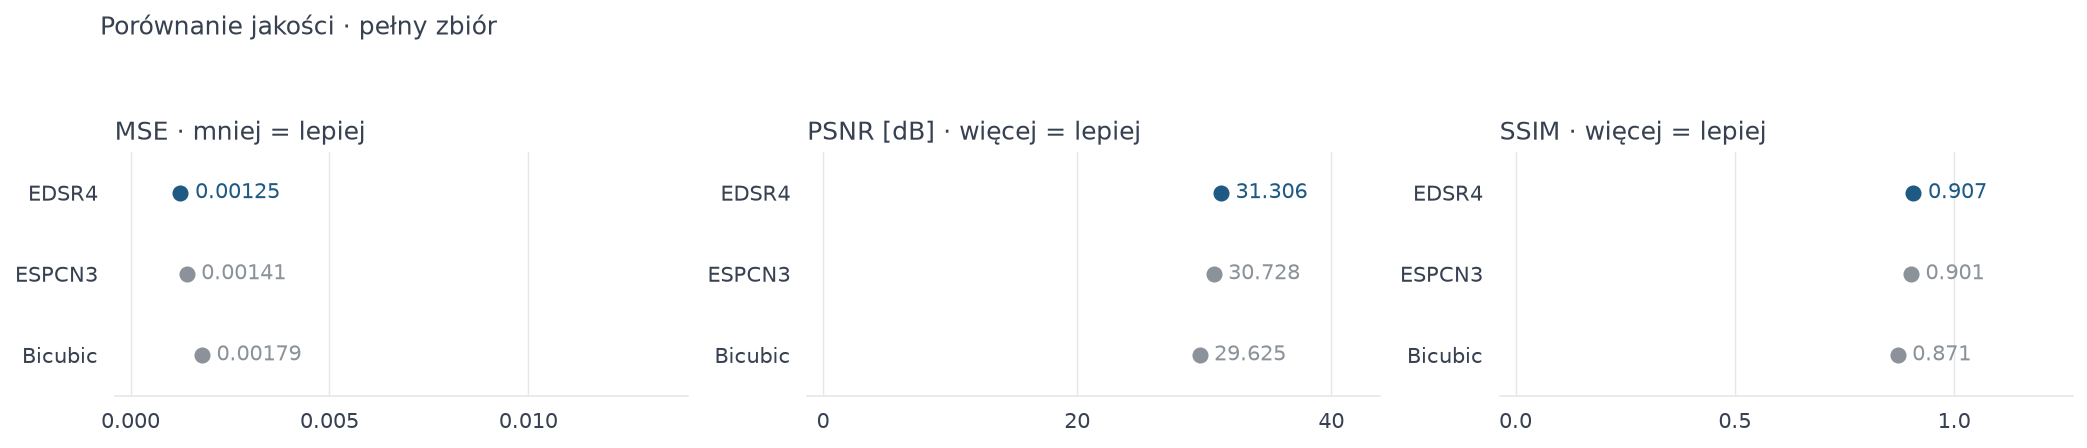

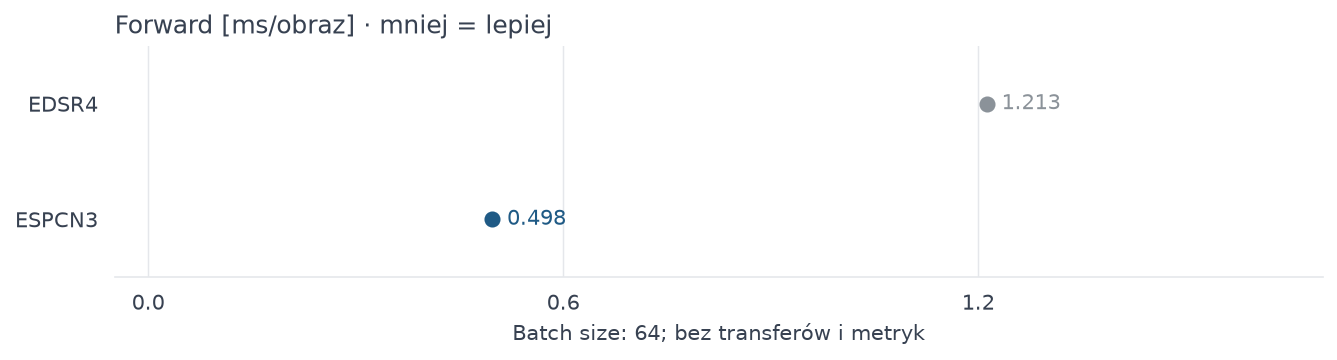

In [5]:
display(DisplayImage(filename=str(RESULTS_PATH / "validation_comparison.png")))
display(DisplayImage(filename=str(RESULTS_PATH / "validation_inference_time.png")))


Oglądamy te same fragmenty i najsłabsze przypadki, a pozostałe grafiki znajdują się w katalogach raportów.

notebooks/igoh/models_weights/experiments/EDSR4_x2_mse_20261109_192402_212926/validation


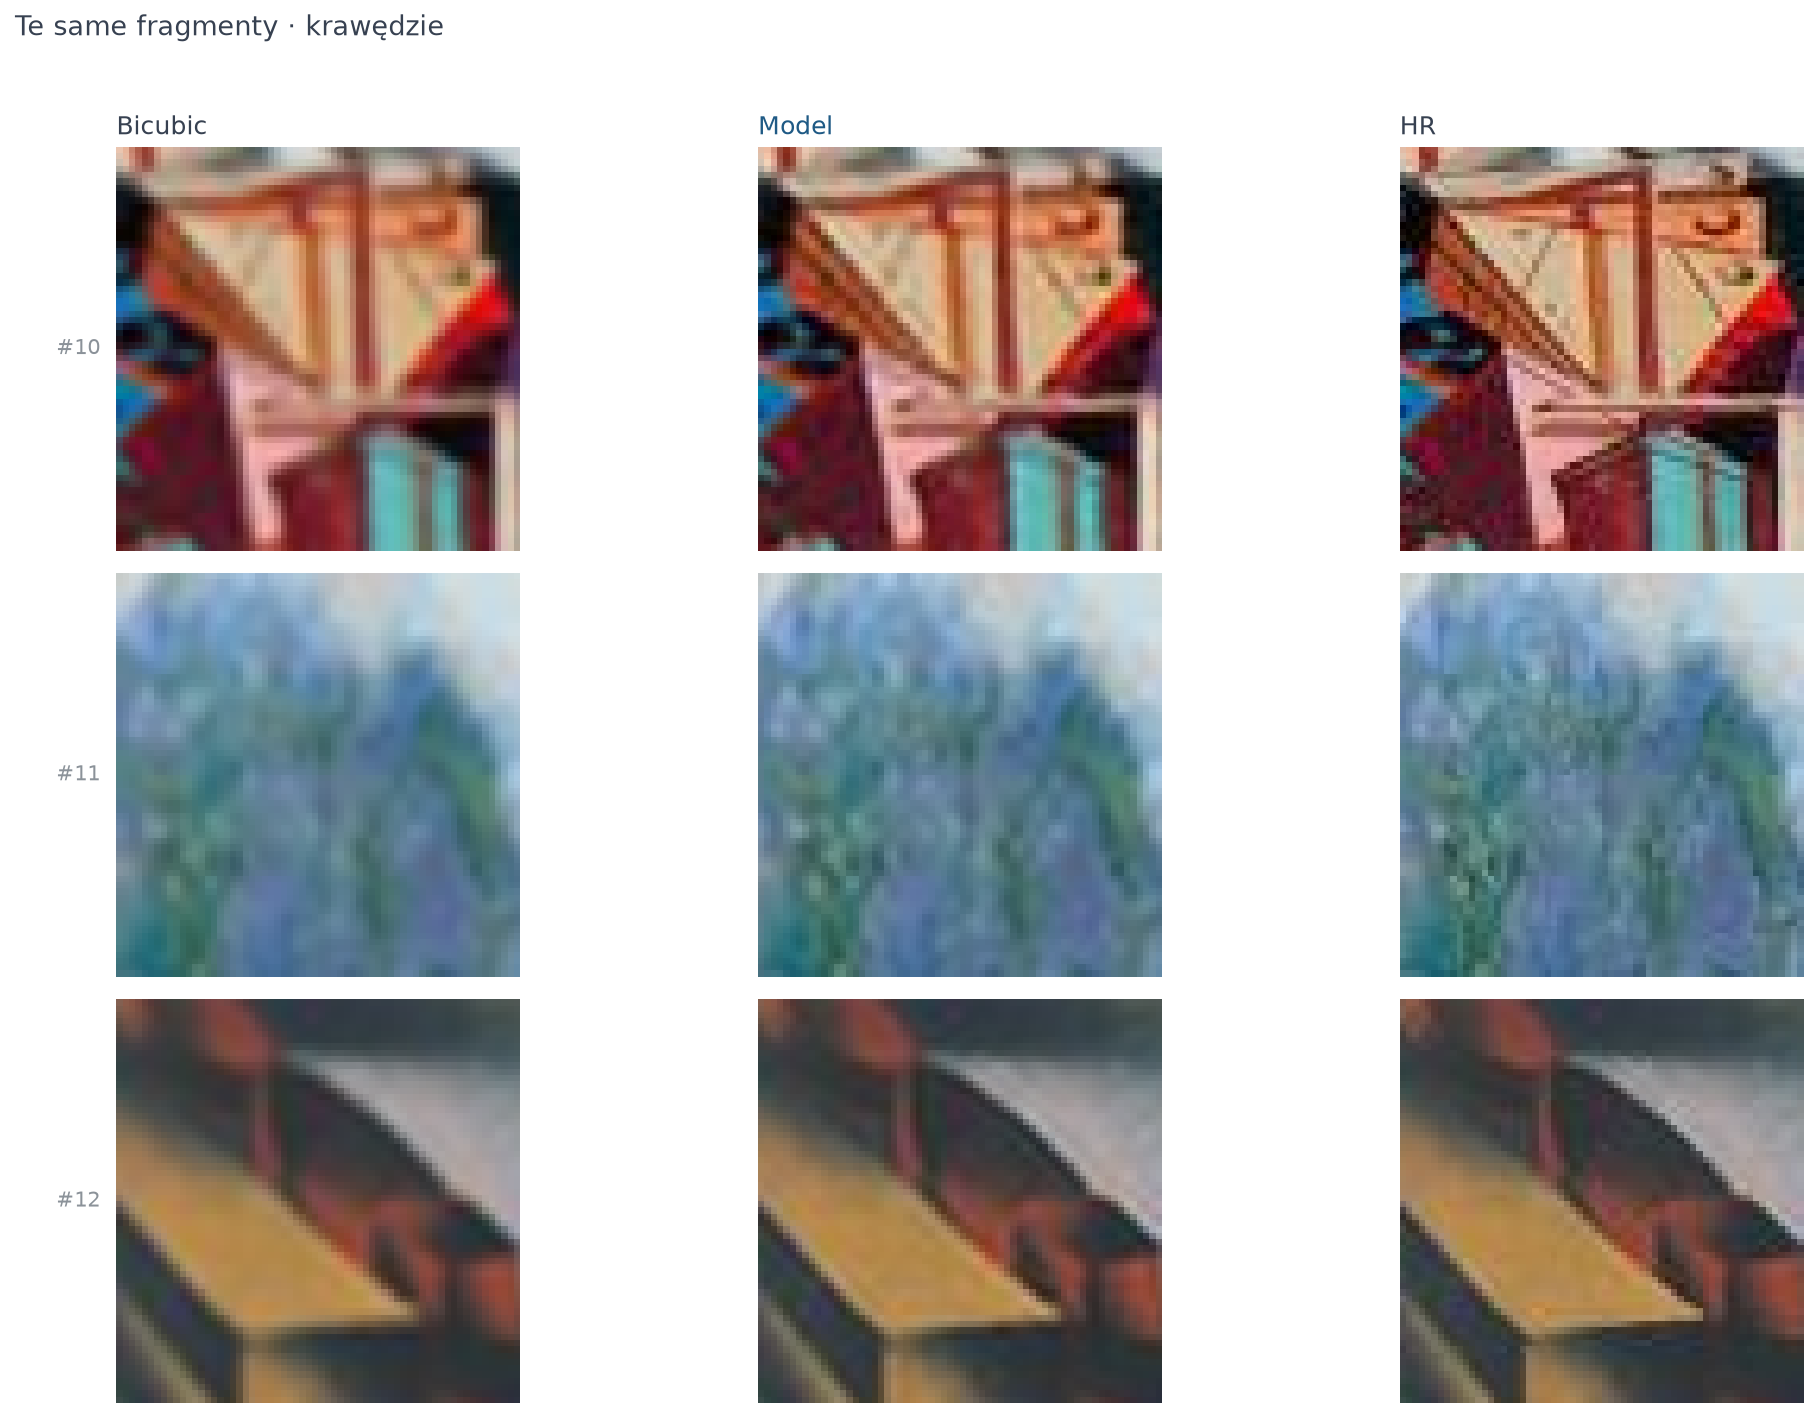

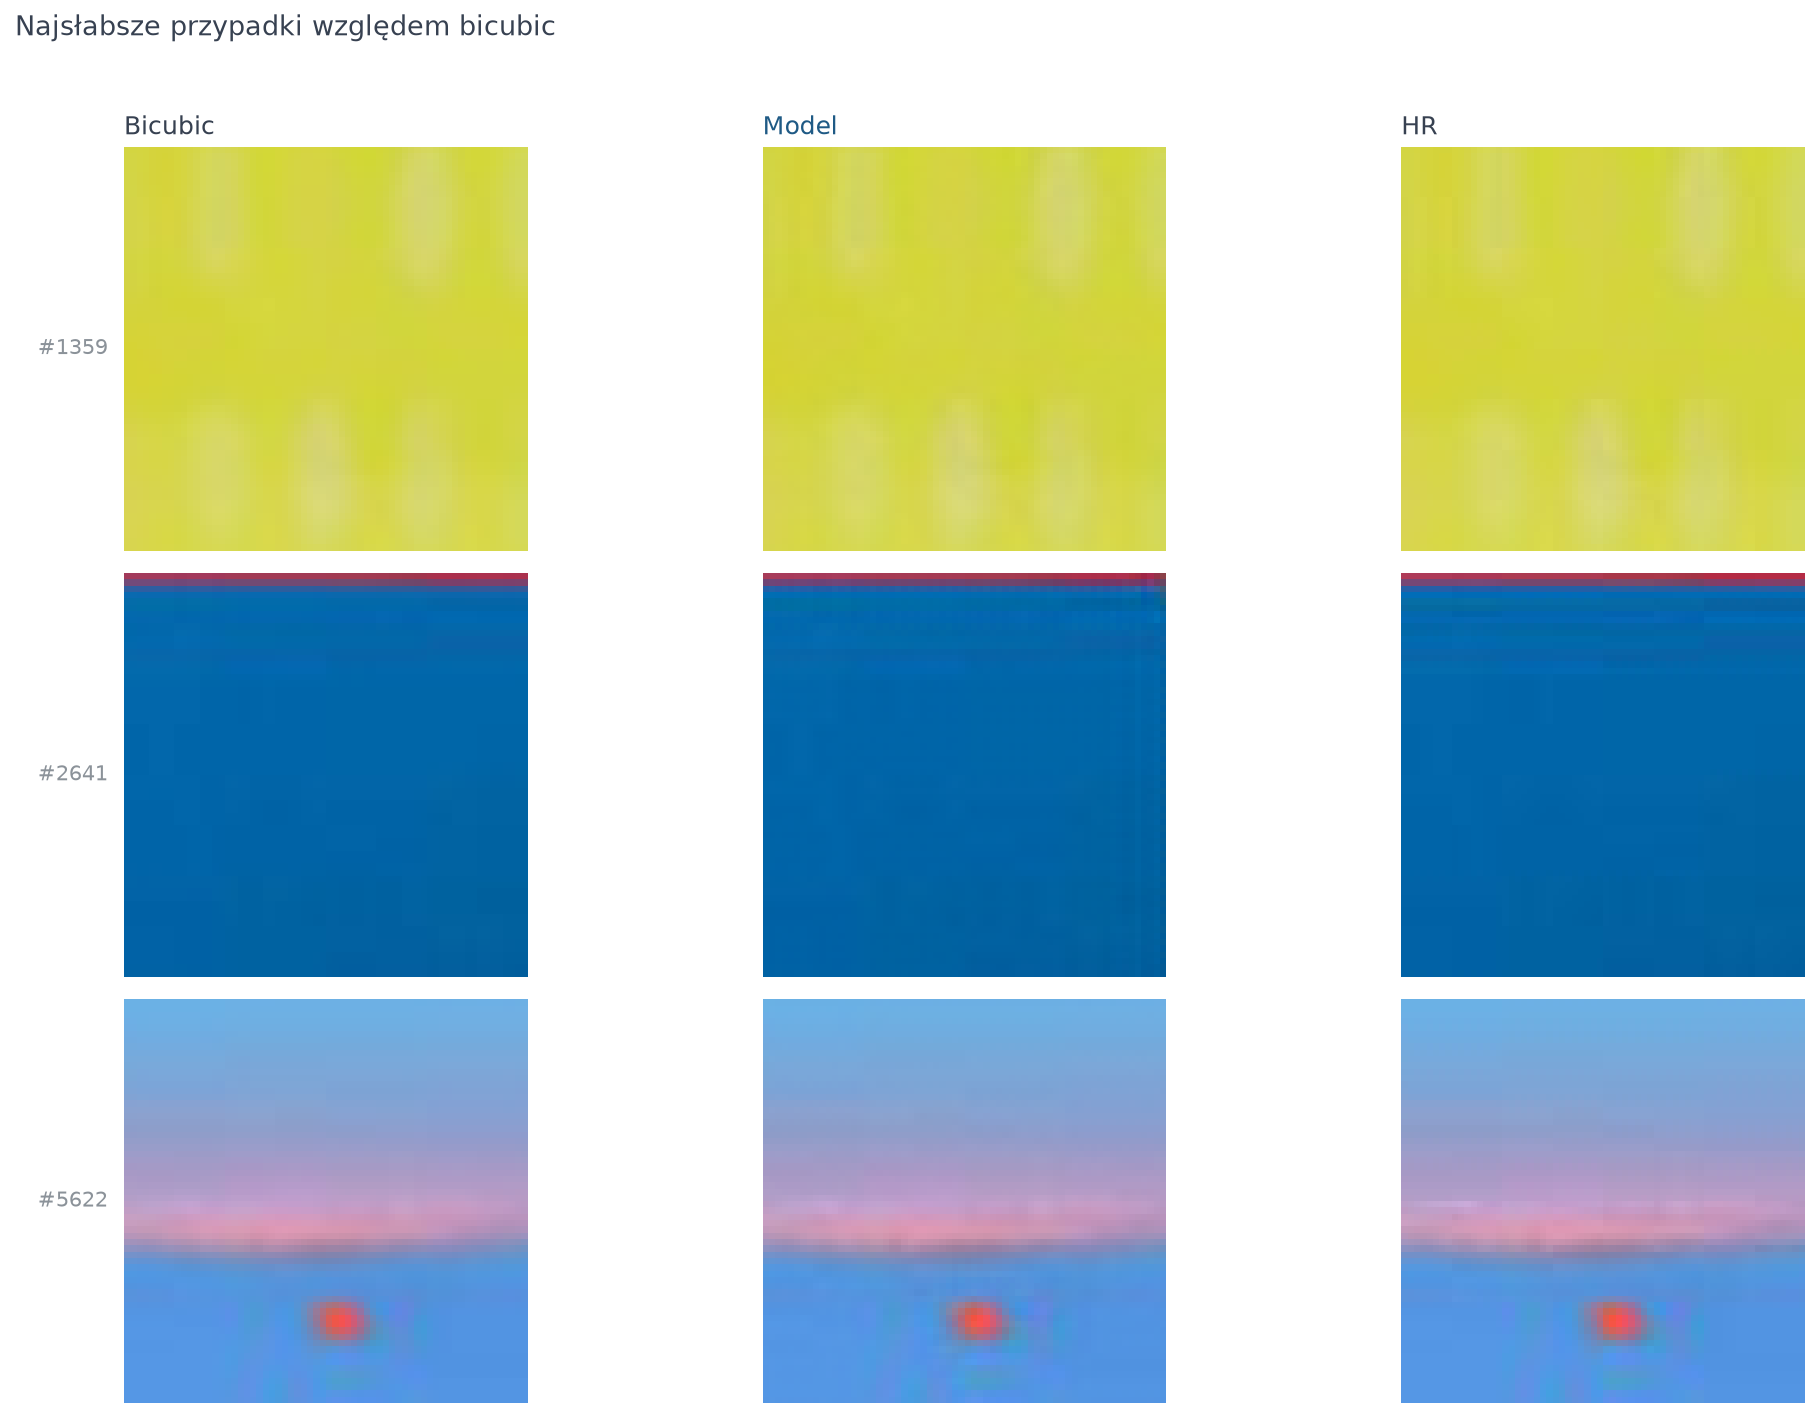

notebooks/igoh/models_weights/experiments/ESPCN3_x2_mse_20261109_185704_405012/validation


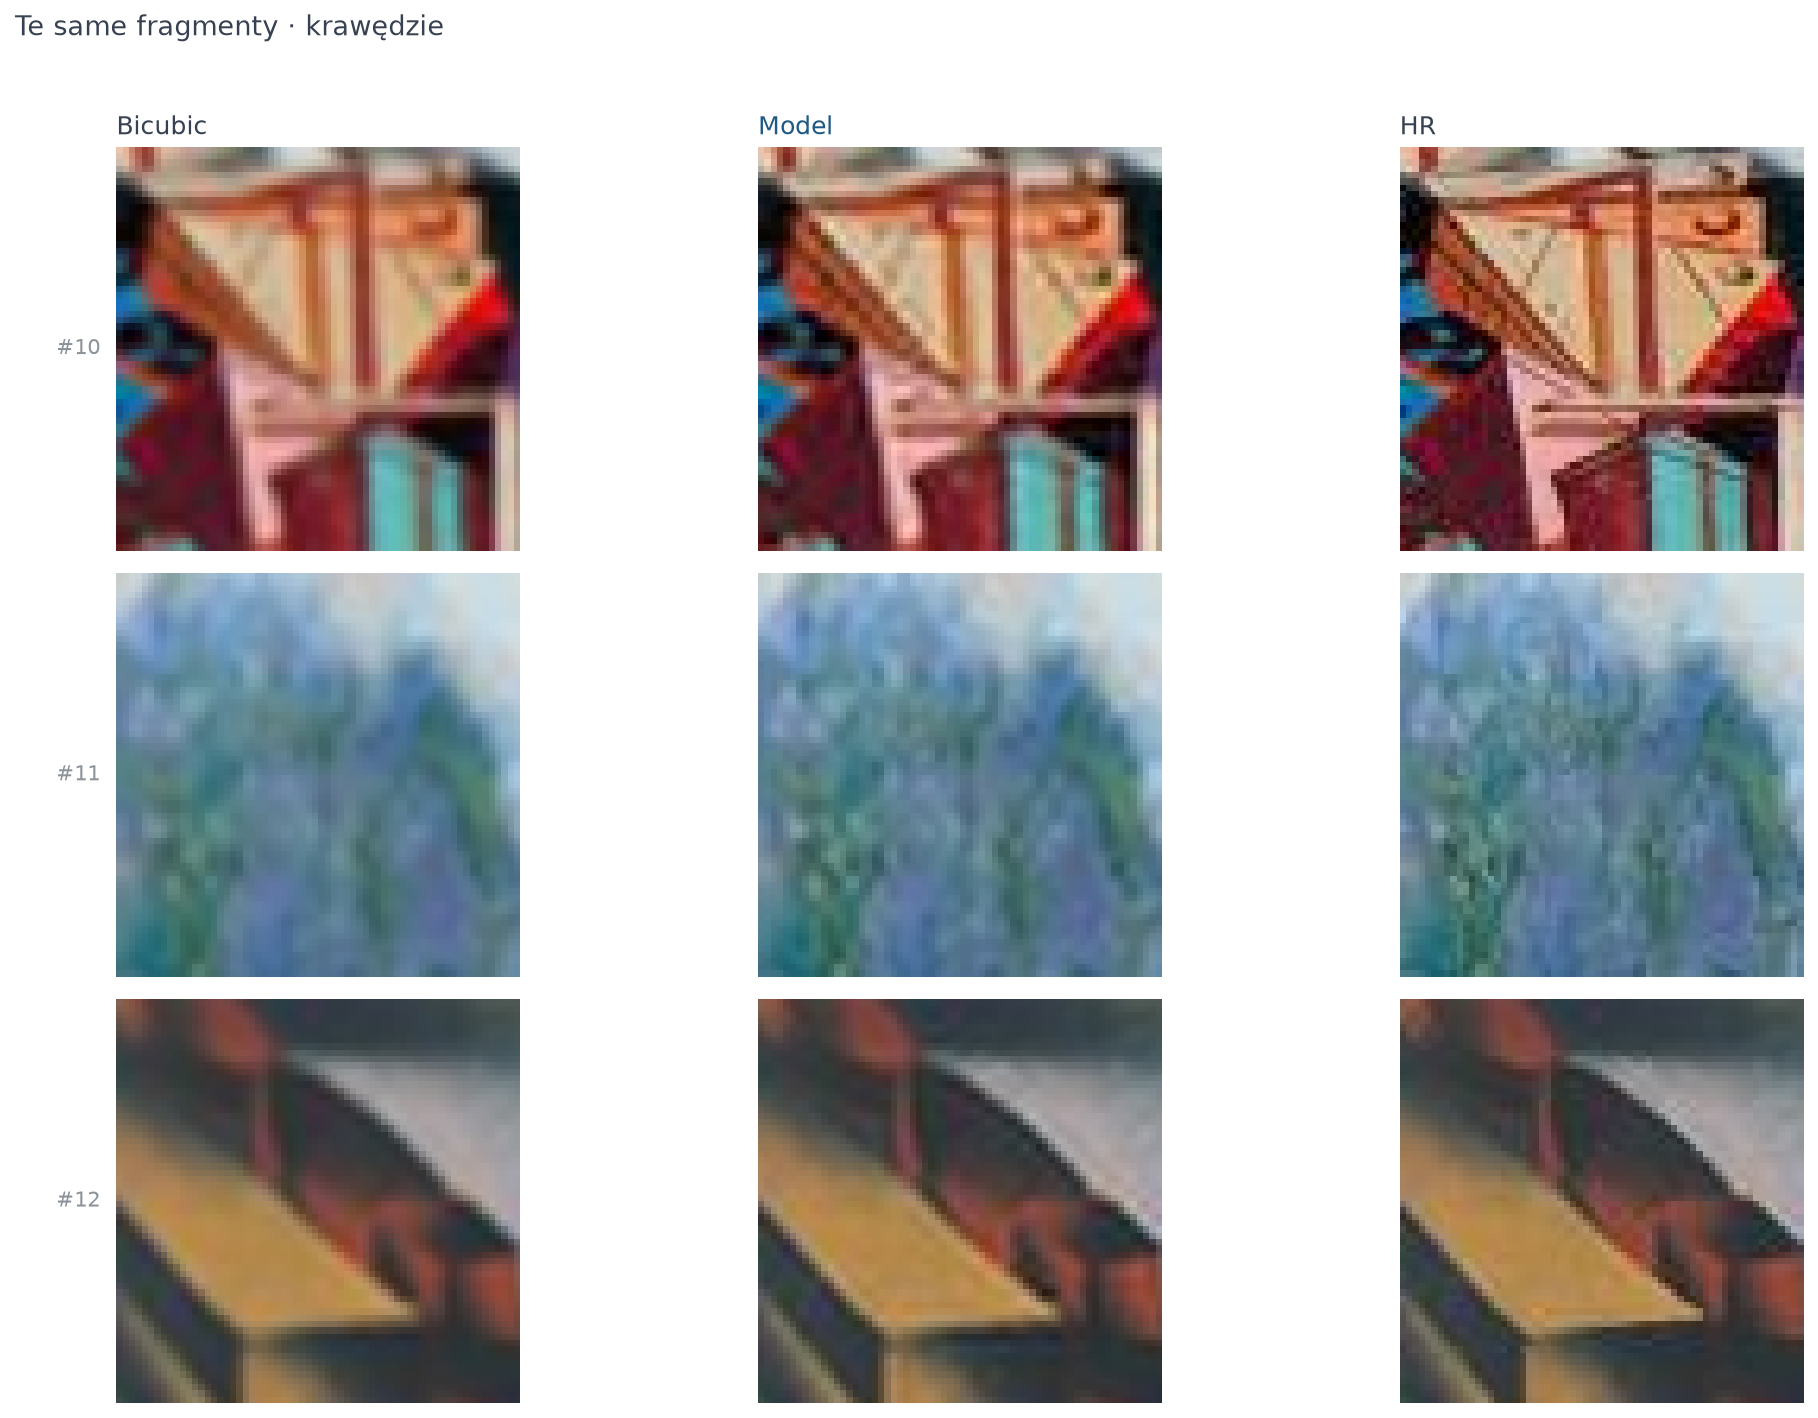

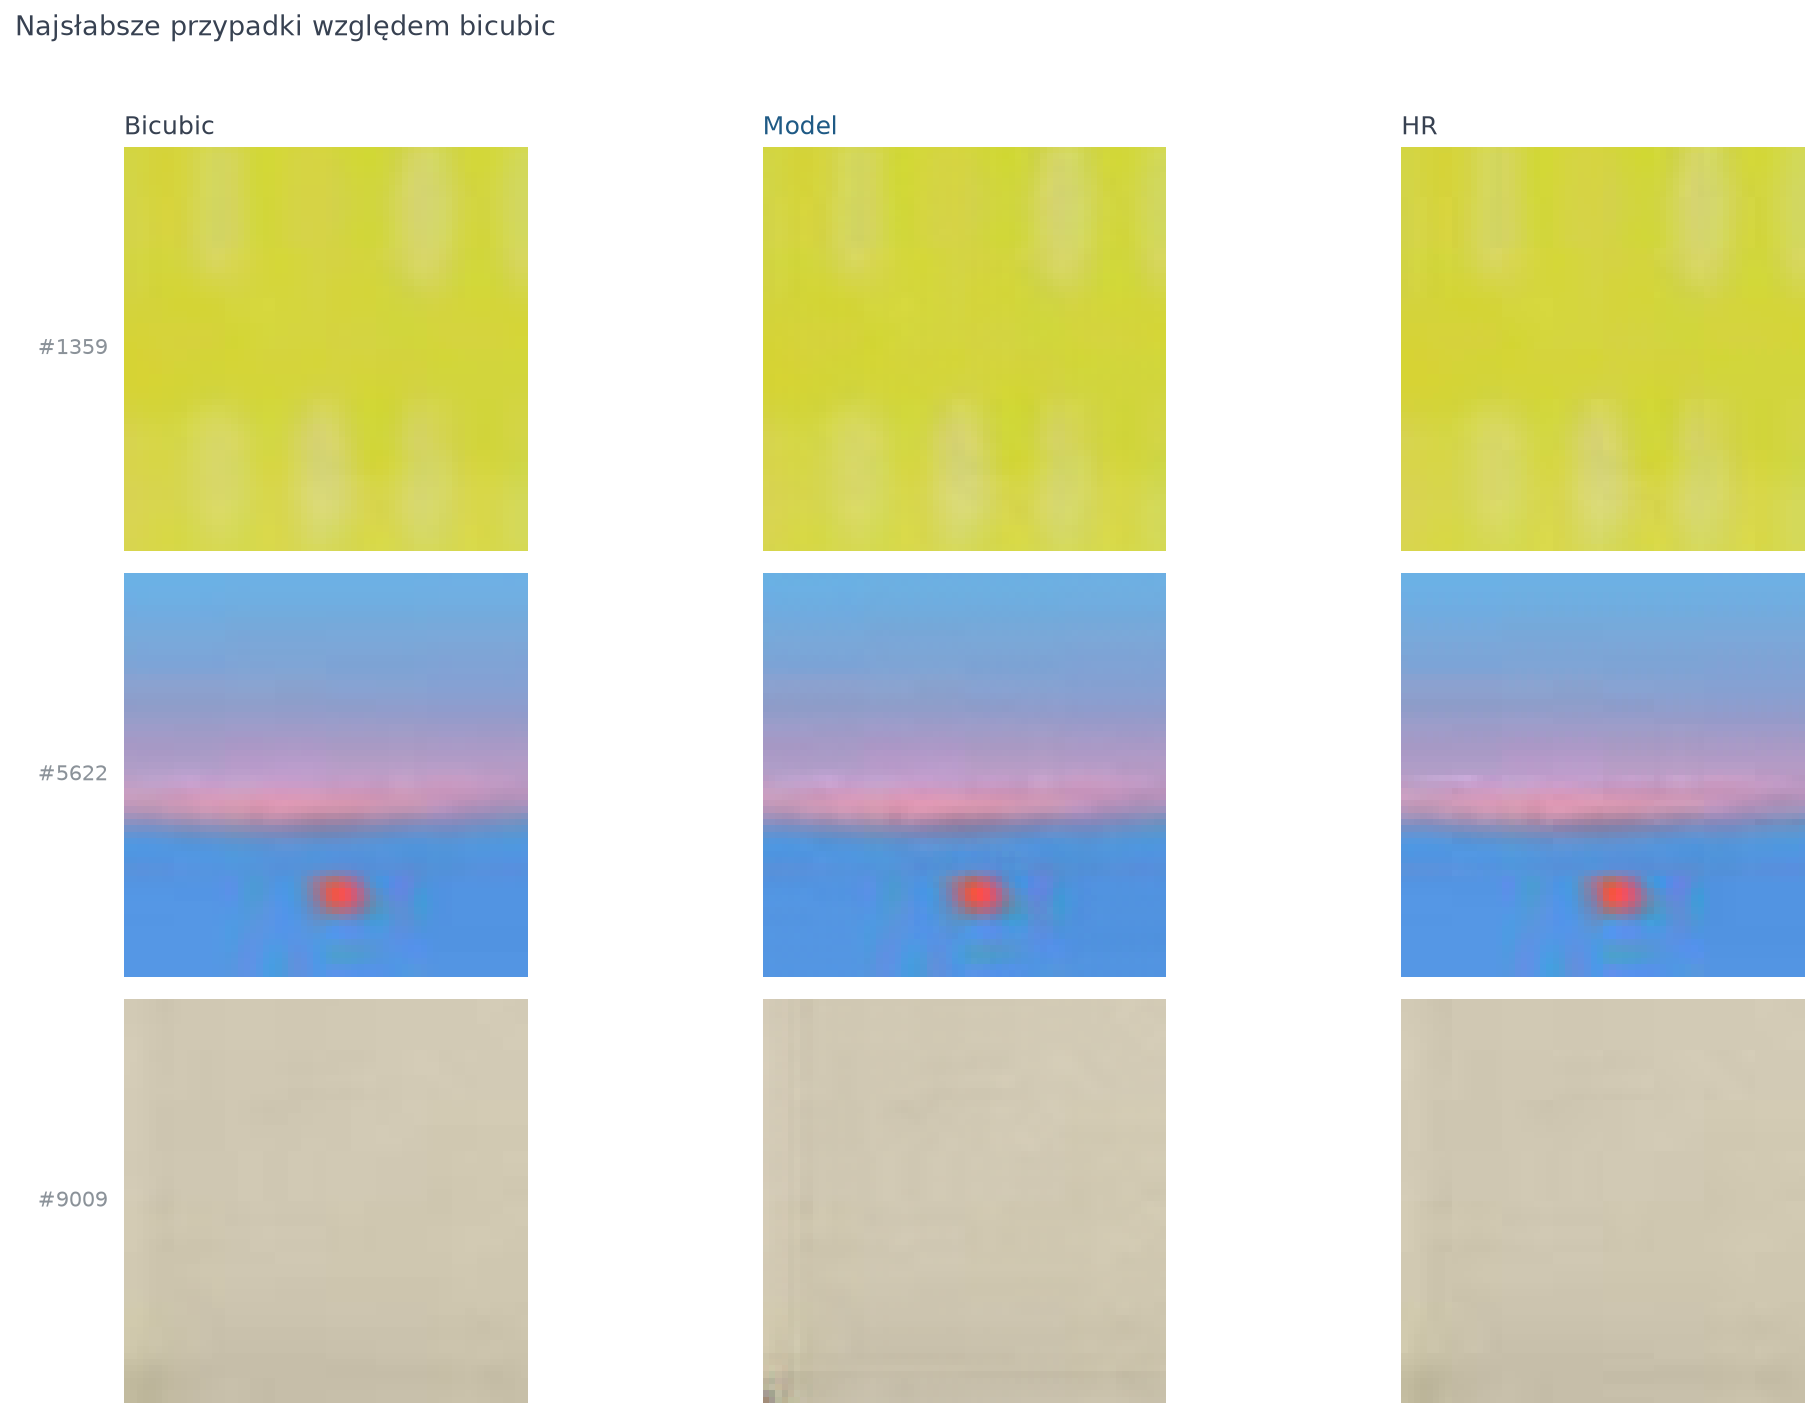

In [6]:
for run_path in RUN_PATHS:
    report_path = run_path / "validation"
    print(display_path(report_path))
    display(DisplayImage(filename=str(report_path / "details.png")))
    display(DisplayImage(filename=str(report_path / "worst_cases.png")))
